# Pruebas de Hipótesis para Dos Poblaciones
## Enfoque "A Pie" (Paso a Paso) vs. Funciones Predefinidas en Python

Este notebook presenta de forma exhaustiva, didáctica y reproducible las pruebas de hipótesis estadísticas fundamentales para comparar **dos poblaciones**, contrastando en cada caso dos enfoques complementarios:
1. **Cálculo "a pie" (paso a paso)**: deduciendo el estadístico de prueba desde sus fundamentos algebraicos, computando los errores estándar, los grados de libertad analíticos, las regiones de rechazo críticas y los p-valores exactos con las distribuciones de `scipy.stats` (`norm`, `t`, `f`).
2. **Uso de funciones predefinidas del ecosistema científico**: empleando funciones especializadas como `scipy.stats.ttest_ind`, `scipy.stats.ttest_rel`, `statsmodels.stats.proportion.proportions_ztest` y pruebas de homogeneidad de varianzas.

---

### Casos Desarrollados:
1. **Diferencia de Medias con Muestras Independientes y $\sigma_1, \sigma_2$ Conocidas** — Prueba $Z$ de dos muestras
2. **Diferencia de Medias con Muestras Independientes y Varianzas Desconocidas Iguales ($\sigma_1^2 = \sigma_2^2$)** — Prueba $t$ combinada / agrupada (*Pooled $t$-test*)
3. **Diferencia de Medias con Muestras Independientes y Varianzas Desconocidas Desiguales ($\sigma_1^2 \neq \sigma_2^2$)** — Prueba $t$ de Welch (*Welch's $t$-test*)
4. **Diferencia de Medias con Muestras Pareadas / Dependientes** — Prueba $t$ pareada (*Paired $t$-test*)
5. **Diferencia de Dos Proporciones Poblacionales ($p_1 - p_2$)** — Prueba $Z$ para dos proporciones
6. **Comparación / Razón de Dos Varianzas Poblacionales ($\sigma_1^2 / \sigma_2^2$)** — Prueba $F$ de Fisher-Snedecor y prueba de Levene

---

### Protocolo Formal de 5 Pasos
Para cada prueba se aplica la metodología estándar de inferencia:
1. **Paso 1:** Formular las hipótesis nula ($H_0$) y alternativa ($H_A$).
2. **Paso 2:** Fijar el nivel de significancia $\alpha$ (típicamente $\alpha = 0.05$).
3. **Paso 3:** Definir el estadístico de prueba y su distribución muestral bajo $H_0$.
4. **Paso 4:** Establecer la regla de decisión (región crítica y regla del p-valor).
5. **Paso 5:** Calcular con los datos muestrales, tomar la decisión e interpretarla en el contexto del problema de ingeniería de software.


In [1]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.weightstats import CompareMeans, DescrStatsW

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 4.2)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
pd.set_option('display.precision', 5)

print("Entorno estadístico para pruebas de dos poblaciones configurado correctamente.")


Entorno estadístico para pruebas de dos poblaciones configurado correctamente.


---

## 1. Diferencia de Medias con Muestras Independientes y $\sigma_1, \sigma_2$ Conocidas — Prueba $Z$

### 1.1 Contexto del Problema e Hipótesis
Dos centros de datos (Región Este y Región Oeste) ejecutan el mismo microservicio. A partir de meses de telemetría histórica de millones de peticiones, las desviaciones estándar poblacionales de la latencia de red se conocen con precisión:
* Región Este: $\sigma_1 = 12.0\text{ ms}$
* Región Oeste: $\sigma_2 = 16.0\text{ ms}$

Se toman muestras independientes de solicitudes en ambos centros de datos para determinar si existe una diferencia sistemática entre las latencias medias:

$$H_0: \mu_1 - \mu_2 = 0 \quad (\mu_1 = \mu_2)$$
$$H_A: \mu_1 - \mu_2 \neq 0 \quad (\mu_1 \neq \mu_2) \quad [\text{bilateral}]$$

Nivel de significancia: $\alpha = 0.05$.


In [2]:
# Simulación sintética del Caso 1
np.random.seed(42)
n1_z, n2_z = 40, 50
sigma1_known, sigma2_known = 12.0, 16.0

# Simulación: Región Este promedia 118 ms, Región Oeste promedia 124 ms
mu1_real, mu2_real = 118.0, 124.0
data1_z = stats.norm.rvs(loc=mu1_real, scale=sigma1_known, size=n1_z, random_state=42)
data2_z = stats.norm.rvs(loc=mu2_real, scale=sigma2_known, size=n2_z, random_state=84)

xbar1_z, xbar2_z = np.mean(data1_z), np.mean(data2_z)
diff_z = xbar1_z - xbar2_z

print(f"--- Muestra Caso 1: Prueba Z de dos muestras ---")
print(f"Grupo 1 (Este):  n1 = {n1_z}, x̄1 = {xbar1_z:.4f} ms, σ1 (conocida) = {sigma1_known:.1f} ms")
print(f"Grupo 2 (Oeste): n2 = {n2_z}, x̄2 = {xbar2_z:.4f} ms, σ2 (conocida) = {sigma2_known:.1f} ms")
print(f"Diferencia muestral (x̄1 - x̄2): {diff_z:.4f} ms")


--- Muestra Caso 1: Prueba Z de dos muestras ---
Grupo 1 (Este):  n1 = 40, x̄1 = 115.3764 ms, σ1 (conocida) = 12.0 ms
Grupo 2 (Oeste): n2 = 50, x̄2 = 117.8520 ms, σ2 (conocida) = 16.0 ms
Diferencia muestral (x̄1 - x̄2): -2.4757 ms


### 1.2 Cálculo "A Pie" (Paso a Paso)
Con $\sigma_1$ y $\sigma_2$ conocidas e independencia entre grupos, la varianza de la diferencia es la suma de varianzas:
$$SE = \sqrt{\frac{\sigma_1^2}{n_1} + \frac{\sigma_2^2}{n_2}}$$

El estadístico de prueba es:
$$Z_{\text{calc}} = \frac{(\bar{x}_1 - \bar{x}_2) - \Delta_0}{\sqrt{\frac{\sigma_1^2}{n_1} + \frac{\sigma_2^2}{n_2}}} \sim N(0, 1)$$

Bajo $H_0$, $\Delta_0 = 0$.


In [3]:
alpha_z = 0.05
delta_0 = 0.0

# 1. Error estándar teórico
se_diff_z = np.sqrt((sigma1_known**2 / n1_z) + (sigma2_known**2 / n2_z))

# 2. Estadístico Z observado
z_calc = (diff_z - delta_0) / se_diff_z

# 3. Valor crítico bilateral
z_crit = stats.norm.ppf(1 - alpha_z / 2)

# 4. P-valor bilateral
p_val_z = 2 * stats.norm.sf(abs(z_calc))

# Intervalo de confianza del 95% para la diferencia de medias
ci_lower_z = diff_z - z_crit * se_diff_z
ci_upper_z = diff_z + z_crit * se_diff_z

print("=== CÁLCULO A PIE (PRUEBA Z DE DOS MEDIAS) ===")
print(f"Error estándar (SE):       {se_diff_z:.4f}")
print(f"Z calculado (Z_obs):       {z_calc:.4f}")
print(f"Valores críticos:          ±{z_crit:.4f}")
print(f"P-valor bilateral:         {p_val_z:.6f}")
print(f"IC 95% de (μ1 - μ2):       [{ci_lower_z:.4f}, {ci_upper_z:.4f}] ms")

decision_z = "Rechazar H0" if abs(z_calc) > z_crit else "No rechazar H0"
print(f"Decisión formal (α={alpha_z}): {decision_z}")


=== CÁLCULO A PIE (PRUEBA Z DE DOS MEDIAS) ===
Error estándar (SE):       2.9530
Z calculado (Z_obs):       -0.8384
Valores críticos:          ±1.9600
P-valor bilateral:         0.401822
IC 95% de (μ1 - μ2):       [-8.2634, 3.3120] ms
Decisión formal (α=0.05): No rechazar H0


### 1.3 Uso de Funciones Predefinidas / Empaquetadas
Empaquetamos una función reusable `ztest_2samp_known_sd` siguiendo la convención de SciPy, y la comparamos con el cálculo a pie.


In [4]:
def ztest_2samp_known_sd(data1, data2, sigma1, sigma2, value=0.0, alternative='two-sided'):
    """Prueba Z para dos muestras independientes con desviaciones estándar conocidas."""
    x1, x2 = np.asarray(data1), np.asarray(data2)
    n1, n2 = len(x1), len(x2)
    diff = np.mean(x1) - np.mean(x2)
    se = np.sqrt((sigma1**2 / n1) + (sigma2**2 / n2))
    stat = (diff - value) / se
    
    if alternative == 'two-sided':
        pval = 2 * stats.norm.sf(abs(stat))
    elif alternative == 'greater':
        pval = stats.norm.sf(stat)
    elif alternative == 'less':
        pval = stats.norm.cdf(stat)
    else:
        raise ValueError("alternative debe ser 'two-sided', 'greater' o 'less'")
    return stat, pval

z_pkg, p_pkg = ztest_2samp_known_sd(data1_z, data2_z, sigma1_known, sigma2_known)

tabla_z2 = pd.DataFrame({
    'Método': ['A pie (fórmula canónica con σ1, σ2)', 'Función empaquetada (ztest_2samp_known_sd)'],
    'Estadístico Z': [z_calc, z_pkg],
    'P-valor': [p_val_z, p_pkg],
    'Decisión (α=0.05)': [decision_z, "Rechazar H0" if p_pkg < alpha_z else "No rechazar H0"]
})
tabla_z2


,Método,Estadístico Z,P-valor,Decisión (α=0.05)
0,"A pie (fórmula canónica con σ1, σ2)",-0.83837,0.40182,No rechazar H0
1,Función empaquetada (ztest_2samp_known_sd),-0.83837,0.40182,No rechazar H0


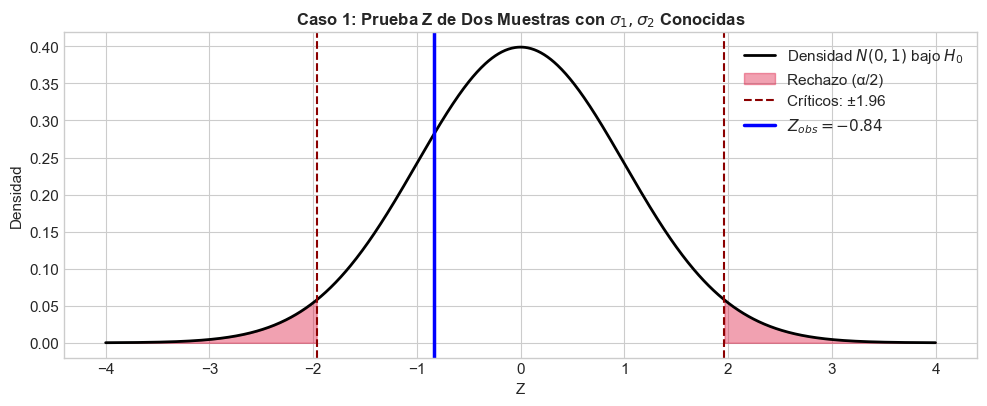

In [5]:
# Visualización gráfica de la distribución Z y la región de rechazo
fig, ax = plt.subplots(figsize=(10, 4.2))
z_axis = np.linspace(-4, 4, 1000)
y_norm = stats.norm.pdf(z_axis, 0, 1)

ax.plot(z_axis, y_norm, 'k-', lw=2, label='Densidad $N(0, 1)$ bajo $H_0$')
ax.fill_between(z_axis, 0, y_norm, where=(z_axis <= -z_crit), color='crimson', alpha=0.4, label='Rechazo (α/2)')
ax.fill_between(z_axis, 0, y_norm, where=(z_axis >= z_crit), color='crimson', alpha=0.4)
ax.axvline(-z_crit, color='darkred', linestyle='--', label=f'Críticos: ±{z_crit:.2f}')
ax.axvline(z_crit, color='darkred', linestyle='--')
ax.axvline(z_calc, color='blue', lw=2.5, label=f'$Z_{{obs}} = {z_calc:.2f}$')

ax.set_title('Caso 1: Prueba Z de Dos Muestras con $\sigma_1, \sigma_2$ Conocidas')
ax.set_xlabel('Z')
ax.set_ylabel('Densidad')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()


---

## 2. Medias con Varianzas Desconocidas Iguales ($\sigma_1^2 = \sigma_2^2$) — Prueba $t$ Agrupada (*Pooled $t$-test*)

### 2.1 Contexto del Problema e Hipótesis
Dos algoritmos de ordenamiento interno (Algoritmo A y Algoritmo B) son evaluados en un banco de pruebas sobre colecciones generadas de idéntico tamaño. Se asume razonablemente que la dispersión de los tiempos es homogénea entre algoritmos ($\sigma_1^2 = \sigma_2^2 = \sigma^2$), pero la varianza común se desconoce.

$$H_0: \mu_A - \mu_B = 0 \quad (\mu_A = \mu_B)$$
$$H_A: \mu_A - \mu_B \neq 0 \quad (\mu_A \neq \mu_B)$$

Nivel de significancia: $\alpha = 0.05$.


In [6]:
# Simulación sintética del Caso 2
np.random.seed(123)
n_A, n_B = 25, 30
sigma_comun = 8.0

# Datos generados con varianza idéntica
data_A = stats.norm.rvs(loc=45.0, scale=sigma_comun, size=n_A, random_state=123)
data_B = stats.norm.rvs(loc=41.5, scale=sigma_comun, size=n_B, random_state=456)

xbar_A, xbar_B = np.mean(data_A), np.mean(data_B)
s_A, s_B = np.std(data_A, ddof=1), np.std(data_B, ddof=1)
df_pooled = n_A + n_B - 2

print(f"--- Muestra Caso 2: t agrupada (pooled) ---")
print(f"Algoritmo A: n_A = {n_A}, x̄_A = {xbar_A:.4f} ms, s_A = {s_A:.4f} ms")
print(f"Algoritmo B: n_B = {n_B}, x̄_B = {xbar_B:.4f} ms, s_B = {s_B:.4f} ms")
print(f"Grados de libertad (nA + nB - 2): {df_pooled}")


--- Muestra Caso 2: t agrupada (pooled) ---
Algoritmo A: n_A = 25, x̄_A = 46.1208 ms, s_A = 9.8536 ms
Algoritmo B: n_B = 30, x̄_B = 43.0807 ms, s_B = 7.6395 ms
Grados de libertad (nA + nB - 2): 53


### 2.2 Cálculo "A Pie" (Paso a Paso)
Al asumir varianza común $\sigma^2$, se combinan las dos varianzas muestrales en la **varianza ponderada o agrupada** ($s_p^2$):
$$s_p^2 = \frac{(n_1 - 1)s_1^2 + (n_2 - 1)s_2^2}{n_1 + n_2 - 2}$$

El error estándar agrupado es:
$$SE_{\text{pool}} = s_p \sqrt{\frac{1}{n_1} + \frac{1}{n_2}}$$

El estadístico de prueba sigue una distribución $t$ con $df = n_1 + n_2 - 2$:
$$t_{\text{calc}} = \frac{\bar{x}_1 - \bar{x}_2}{s_p \sqrt{\frac{1}{n_1} + \frac{1}{n_2}}} \sim t_{n_1 + n_2 - 2}$$


In [7]:
alpha_pooled = 0.05

# 1. Varianza agrupada (sp^2)
sp2 = ((n_A - 1) * s_A**2 + (n_B - 1) * s_B**2) / df_pooled
sp = np.sqrt(sp2)

# 2. Error estándar agrupado
se_pooled = sp * np.sqrt((1 / n_A) + (1 / n_B))

# 3. Estadístico t
diff_AB = xbar_A - xbar_B
t_calc_pooled = diff_AB / se_pooled

# 4. Valor crítico bilateral y P-valor
t_crit_pooled = stats.t.ppf(1 - alpha_pooled / 2, df=df_pooled)
p_val_pooled = 2 * stats.t.sf(abs(t_calc_pooled), df=df_pooled)

print("=== CÁLCULO A PIE (PRUEBA t AGRUPADA / POOLED) ===")
print(f"Varianza agrupada (sp²):  {sp2:.4f} | sp = {sp:.4f}")
print(f"Error estándar (SE_pool): {se_pooled:.4f}")
print(f"t calculado (t_obs):      {t_calc_pooled:.4f}")
print(f"Valores críticos:         ±{t_crit_pooled:.4f}")
print(f"P-valor bilateral:        {p_val_pooled:.5f}")

decision_pooled = "Rechazar H0" if abs(t_calc_pooled) > t_crit_pooled else "No rechazar H0"
print(f"Decisión formal (α={alpha_pooled}): {decision_pooled}")


=== CÁLCULO A PIE (PRUEBA t AGRUPADA / POOLED) ===
Varianza agrupada (sp²):  75.9008 | sp = 8.7121
Error estándar (SE_pool): 2.3592
t calculado (t_obs):      1.2886
Valores críticos:         ±2.0057
P-valor bilateral:        0.20314
Decisión formal (α=0.05): No rechazar H0


### 2.3 Uso de Funciones Predefinidas (`scipy.stats.ttest_ind` con `equal_var=True`)
En SciPy, `scipy.stats.ttest_ind(..., equal_var=True)` implementa exactamente la prueba $t$ de Student agrupada.


In [8]:
# Ejecución con scipy.stats.ttest_ind
res_scipy_pooled = stats.ttest_ind(data_A, data_B, equal_var=True, alternative='two-sided')

tabla_pooled = pd.DataFrame({
    'Método': ['A pie (fórmulas agrupadas sp y SE)', 'scipy.stats.ttest_ind (equal_var=True)'],
    't': [t_calc_pooled, res_scipy_pooled.statistic],
    'P-valor': [p_val_pooled, res_scipy_pooled.pvalue],
    'Diferencia absoluta': [0.0, abs(p_val_pooled - res_scipy_pooled.pvalue)],
    'Decisión (α=0.05)': [decision_pooled, "Rechazar H0" if res_scipy_pooled.pvalue < alpha_pooled else "No rechazar H0"]
})
tabla_pooled


,Método,t,P-valor,Diferencia absoluta,Decisión (α=0.05)
0,A pie (fórmulas agrupadas sp y SE),1.28858,0.20314,0.0,No rechazar H0
1,scipy.stats.ttest_ind (equal_var=True),1.28858,0.20314,0.0,No rechazar H0


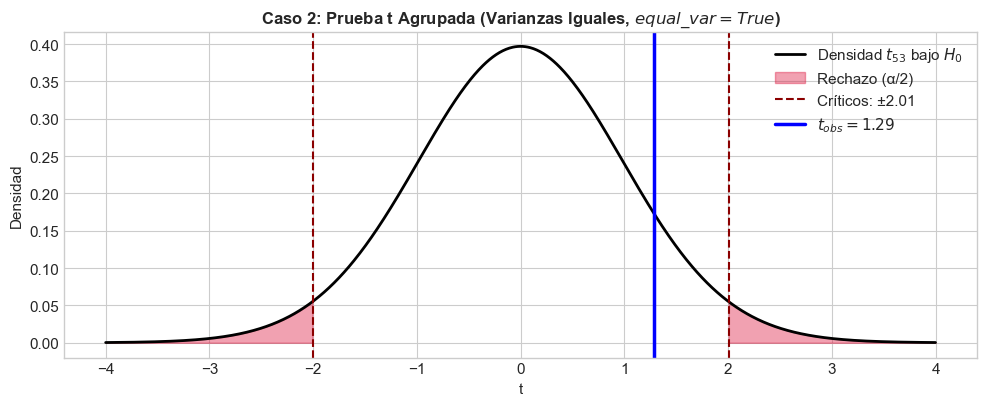

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.2))
t_grid = np.linspace(-4, 4, 1000)
y_t = stats.t.pdf(t_grid, df=df_pooled)

ax.plot(t_grid, y_t, 'k-', lw=2, label=f'Densidad $t_{{{df_pooled}}}$ bajo $H_0$')
ax.fill_between(t_grid, 0, y_t, where=(t_grid <= -t_crit_pooled), color='crimson', alpha=0.4, label='Rechazo (α/2)')
ax.fill_between(t_grid, 0, y_t, where=(t_grid >= t_crit_pooled), color='crimson', alpha=0.4)
ax.axvline(-t_crit_pooled, color='darkred', linestyle='--', label=f'Críticos: ±{t_crit_pooled:.2f}')
ax.axvline(t_crit_pooled, color='darkred', linestyle='--')
ax.axvline(t_calc_pooled, color='blue', lw=2.5, label=f'$t_{{obs}} = {t_calc_pooled:.2f}$')

ax.set_title('Caso 2: Prueba t Agrupada (Varianzas Iguales, $equal\_var=True$)')
ax.set_xlabel('t')
ax.set_ylabel('Densidad')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()


---

## 3. Medias con Varianzas Desiguales ($\sigma_1^2 \neq \sigma_2^2$) — Prueba $t$ de Welch

### 3.1 Contexto del Problema e Hipótesis
En la Sesión 8 del curso se analiza el benchmark de rendimiento entre la versión *Baseline* y la versión *Optimized* sobre casos de prueba independientes:
* Las dos versiones no solo tienen medias potencialmente distintas, sino que la optimización puede cambiar la dispersión de la latencia ($\sigma_1^2 \neq \sigma_2^2$).
* La prueba **$t$ de Welch** es el procedimiento moderno recomendado por defecto para muestras independientes, ya que no asume igualdad de varianzas poblacionales.

$$H_0: \mu_{opt} - \mu_{base} = 0$$
$$H_A: \mu_{opt} - \mu_{base} \neq 0 \quad [\text{bilateral}]$$

Nivel de significancia: $\alpha = 0.05$.


In [10]:
# Simulación sintética del Caso 3 (con varianzas notablemente distintas)
np.random.seed(80)
n_base, n_opt = 80, 80

# Parámetros acordes a la Sesión 8
base_data = stats.norm.rvs(loc=240.48, scale=35.2, size=n_base, random_state=80)
opt_data = stats.norm.rvs(loc=231.76, scale=28.4, size=n_opt, random_state=160)

xbar_base, xbar_opt = np.mean(base_data), np.mean(opt_data)
s_base, s_opt = np.std(base_data, ddof=1), np.std(opt_data, ddof=1)
diff_welch = xbar_opt - xbar_base

print(f"--- Muestra Caso 3: Prueba t de Welch ---")
print(f"Baseline:  n = {n_base}, x̄ = {xbar_base:.4f} ms, s = {s_base:.4f} ms, s² = {s_base**2:.2f}")
print(f"Optimized: n = {n_opt}, x̄ = {xbar_opt:.4f} ms, s = {s_opt:.4f} ms, s² = {s_opt**2:.2f}")
print(f"Diferencia muestral (Optimized - Baseline): {diff_welch:.4f} ms")


--- Muestra Caso 3: Prueba t de Welch ---
Baseline:  n = 80, x̄ = 244.9200 ms, s = 33.2489 ms, s² = 1105.49
Optimized: n = 80, x̄ = 233.4880 ms, s = 28.4646 ms, s² = 810.23
Diferencia muestral (Optimized - Baseline): -11.4321 ms


### 3.2 Cálculo "A Pie" (Paso a Paso)
El error estándar de Welch no combina varianzas:
$$SE_{\text{Welch}} = \sqrt{\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}}$$

El estadístico de prueba es:
$$t = \frac{(\bar{x}_1 - \bar{x}_2) - 0}{SE_{\text{Welch}}}$$

Los grados de libertad se calculan mediante la **ecuación de Welch-Satterthwaite**:
$$df_{\text{Welch}} = \frac{\left(\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}\right)^2}{\frac{(s_1^2/n_1)^2}{n_1 - 1} + \frac{(s_2^2/n_2)^2}{n_2 - 1}}$$


In [11]:
alpha_welch = 0.05

# 1. Varianzas de las medias muestrales
v_base = (s_base**2) / n_base
v_opt = (s_opt**2) / n_opt

# 2. Error estándar de Welch
se_welch = np.sqrt(v_base + v_opt)

# 3. Estadístico t
t_calc_welch = diff_welch / se_welch

# 4. Grados de libertad Welch-Satterthwaite
df_welch = ((v_base + v_opt)**2) / ((v_base**2 / (n_base - 1)) + (v_opt**2 / (n_opt - 1)))

# 5. Valor crítico y P-valor
t_crit_welch = stats.t.ppf(1 - alpha_welch / 2, df=df_welch)
p_val_welch = 2 * stats.t.sf(abs(t_calc_welch), df=df_welch)

print("=== CÁLCULO A PIE (PRUEBA t DE WELCH) ===")
print(f"Error estándar (SE_Welch):          {se_welch:.4f} ms")
print(f"Grados de libertad (df_Welch):       {df_welch:.4f}")
print(f"t calculado (t_obs):                 {t_calc_welch:.4f}")
print(f"Valores críticos:                    ±{t_crit_welch:.4f}")
print(f"P-valor bilateral:                   {p_val_welch:.5f}")

decision_welch = "Rechazar H0" if abs(t_calc_welch) > t_crit_welch else "No rechazar H0"
print(f"Decisión formal (α={alpha_welch}):        {decision_welch}")


=== CÁLCULO A PIE (PRUEBA t DE WELCH) ===
Error estándar (SE_Welch):          4.8935 ms
Grados de libertad (df_Welch):       154.3339
t calculado (t_obs):                 -2.3362
Valores críticos:                    ±1.9755
P-valor bilateral:                   0.02077
Decisión formal (α=0.05):        Rechazar H0


### 3.3 Uso de Funciones Predefinidas (`scipy.stats.ttest_ind` con `equal_var=False`)
En SciPy, fijar `equal_var=False` ejecuta la prueba de Welch.


In [12]:
# Ejecución oficial con scipy.stats
res_scipy_welch = stats.ttest_ind(opt_data, base_data, equal_var=False, alternative='two-sided')

tabla_welch = pd.DataFrame({
    'Método': ['A pie (fórmulas de Welch-Satterthwaite)', 'scipy.stats.ttest_ind (equal_var=False)'],
    't': [t_calc_welch, res_scipy_welch.statistic],
    'Grados de libertad': [df_welch, res_scipy_welch.df],
    'P-valor': [p_val_welch, res_scipy_welch.pvalue],
    'Diferencia absoluta': [0.0, abs(p_val_welch - res_scipy_welch.pvalue)],
    'Decisión (α=0.05)': [decision_welch, "Rechazar H0" if res_scipy_welch.pvalue < alpha_welch else "No rechazar H0"]
})
tabla_welch


,Método,t,Grados de libertad,P-valor,Diferencia absoluta,Decisión (α=0.05)
0,A pie (fórmulas de Welch-Satterthwaite),-2.33617,154.33391,0.02077,0.00000e+00,Rechazar H0
1,scipy.stats.ttest_ind (equal_var=False),-2.33617,154.33391,0.02077,3.46945e-17,Rechazar H0


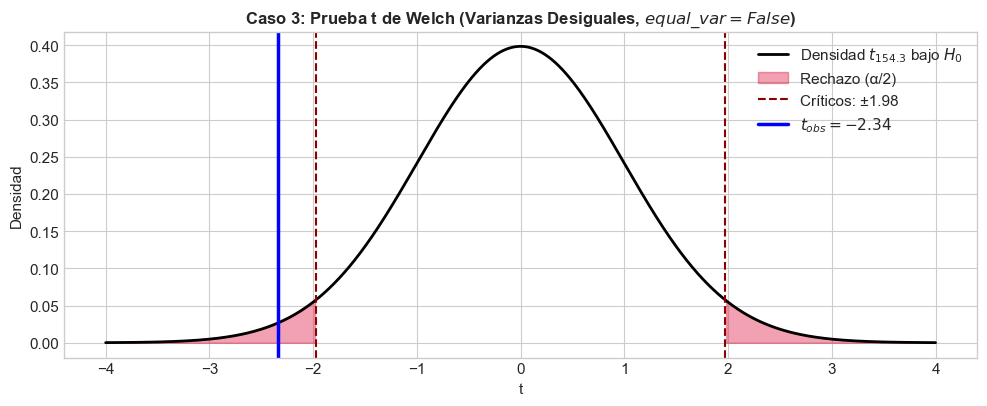

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.2))
t_grid_w = np.linspace(-4, 4, 1000)
y_tw = stats.t.pdf(t_grid_w, df=df_welch)

ax.plot(t_grid_w, y_tw, 'k-', lw=2, label=f'Densidad $t_{{{df_welch:.1f}}}$ bajo $H_0$')
ax.fill_between(t_grid_w, 0, y_tw, where=(t_grid_w <= -t_crit_welch), color='crimson', alpha=0.4, label='Rechazo (α/2)')
ax.fill_between(t_grid_w, 0, y_tw, where=(t_grid_w >= t_crit_welch), color='crimson', alpha=0.4)
ax.axvline(-t_crit_welch, color='darkred', linestyle='--', label=f'Críticos: ±{t_crit_welch:.2f}')
ax.axvline(t_crit_welch, color='darkred', linestyle='--')
ax.axvline(t_calc_welch, color='blue', lw=2.5, label=f'$t_{{obs}} = {t_calc_welch:.2f}$')

ax.set_title('Caso 3: Prueba t de Welch (Varianzas Desiguales, $equal\_var=False$)')
ax.set_xlabel('t')
ax.set_ylabel('Densidad')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()


---

## 4. Medias con Muestras Pareadas / Dependientes — Prueba $t$ Pareada

### 4.1 Contexto del Problema e Hipótesis
En un diseño de mediciones pareadas, cada caso de prueba corre **bajo ambas versiones** (Baseline y Optimized). Esto controla la heterogeneidad intrínseca de dificultad entre casos de prueba.

La unidad de análisis es la diferencia intra-par:
$$d_i = x_{i, opt} - x_{i, base}$$

Las hipótesis son:
$$H_0: \mu_d = 0 \quad (\text{la media poblacional de las diferencias es cero})$$
$$H_A: \mu_d \neq 0 \quad (\text{existe una diferencia sistemática entre versiones})$$
(o unilateral $H_A: \mu_d < 0$ para mejora en latencia). Nivel de significancia: $\alpha = 0.05$.


In [14]:
# Simulación sintética del Caso 4 (diseño pareado con correlación r > 0)
np.random.seed(60)
n_pairs = 60

# Heterogeneidad base por caso (algunos casos son inherentemente más lentos que otros)
dificultad_caso = stats.uniform.rvs(loc=150, scale=120, size=n_pairs, random_state=60)

# Latencias pareadas: la optimización reduce ~16 ms en promedio
base_paired = dificultad_caso + stats.norm.rvs(loc=0, scale=8, size=n_pairs, random_state=120)
opt_paired = dificultad_caso - 16.22 + stats.norm.rvs(loc=0, scale=8, size=n_pairs, random_state=180)

# Vector de diferencias dentro de cada caso
diferencias = opt_paired - base_paired

d_bar = np.mean(diferencias)
s_d = np.std(diferencias, ddof=1)
df_paired = n_pairs - 1
correlacion = np.corrcoef(base_paired, opt_paired)[0, 1]

print(f"--- Muestra Caso 4: Diseño Pareado (n = {n_pairs} pares) ---")
print(f"Media de diferencias (d̄):      {d_bar:.4f} ms")
print(f"Desviación de diferencias (sd): {s_d:.4f} ms")
print(f"Correlación entre pares (r):   {correlacion:.4f} (alta correlación intra-caso)")


--- Muestra Caso 4: Diseño Pareado (n = 60 pares) ---
Media de diferencias (d̄):      -18.6748 ms
Desviación de diferencias (sd): 10.3284 ms
Correlación entre pares (r):   0.9612 (alta correlación intra-caso)


### 4.2 Cálculo "A Pie" (Paso a Paso)
Una prueba $t$ pareada es formalmente equivalente a una prueba $t$ de **una muestra** aplicada sobre el vector de diferencias $\{d_i\}_{i=1}^n$:
$$SE_d = \frac{s_d}{\sqrt{n}}$$
$$t_{\text{calc}} = \frac{\bar{d} - \mu_{d,0}}{\frac{s_d}{\sqrt{n}}} \sim t_{n-1}$$


In [15]:
alpha_paired = 0.05

# 1. Error estándar de las diferencias
se_d = s_d / np.sqrt(n_pairs)

# 2. Estadístico t
t_calc_paired = (d_bar - 0.0) / se_d

# 3. Valores críticos y P-valor
t_crit_paired = stats.t.ppf(1 - alpha_paired / 2, df=df_paired)
p_val_paired = 2 * stats.t.sf(abs(t_calc_paired), df=df_paired)

# Intervalo de confianza del 95% para la diferencia media
ci_lower_d = d_bar - t_crit_paired * se_d
ci_upper_d = d_bar + t_crit_paired * se_d

print("=== CÁLCULO A PIE (PRUEBA t PAREADA) ===")
print(f"Error estándar de diferencias (sd/√n): {se_d:.4f} ms")
print(f"t calculado (t_obs):                   {t_calc_paired:.4f}")
print(f"Valores críticos:                      ±{t_crit_paired:.4f}")
print(f"P-valor bilateral:                     {p_val_paired:.4e}")
print(f"IC 95% para la media de diferencias:   [{ci_lower_d:.4f}, {ci_upper_d:.4f}] ms")

decision_paired = "Rechazar H0" if abs(t_calc_paired) > t_crit_paired else "No rechazar H0"
print(f"Decisión formal (α={alpha_paired}):          {decision_paired}")


=== CÁLCULO A PIE (PRUEBA t PAREADA) ===
Error estándar de diferencias (sd/√n): 1.3334 ms
t calculado (t_obs):                   -14.0056
Valores críticos:                      ±2.0010
P-valor bilateral:                     2.0372e-20
IC 95% para la media de diferencias:   [-21.3429, -16.0067] ms
Decisión formal (α=0.05):          Rechazar H0


### 4.3 Uso de Funciones Predefinidas (`scipy.stats.ttest_rel`)
SciPy provee `scipy.stats.ttest_rel(a, b)` para muestras relacionadas o dependientes. Es idéntica a ejecutar `scipy.stats.ttest_1samp(diferencias, 0.0)`.


In [16]:
# Ejecución con scipy.stats.ttest_rel y verificación con ttest_1samp
res_ttest_rel = stats.ttest_rel(opt_paired, base_paired, alternative='two-sided')
res_ttest_1samp_diff = stats.ttest_1samp(diferencias, popmean=0.0, alternative='two-sided')

tabla_paired = pd.DataFrame({
    'Método': [
        'A pie (fórmulas d̄ y sd/√n)',
        'scipy.stats.ttest_rel(opt, base)',
        'scipy.stats.ttest_1samp(diferencias, 0)'
    ],
    't': [t_calc_paired, res_ttest_rel.statistic, res_ttest_1samp_diff.statistic],
    'P-valor': [p_val_paired, res_ttest_rel.pvalue, res_ttest_1samp_diff.pvalue],
    'Decisión (α=0.05)': [
        decision_paired,
        "Rechazar H0" if res_ttest_rel.pvalue < alpha_paired else "No rechazar H0",
        "Rechazar H0" if res_ttest_1samp_diff.pvalue < alpha_paired else "No rechazar H0"
    ]
})
tabla_paired


,Método,t,P-valor,Decisión (α=0.05)
0,A pie (fórmulas d̄ y sd/√n),-14.00556,2.03720e-20,Rechazar H0
1,"scipy.stats.ttest_rel(opt, base)",-14.00556,2.03720e-20,Rechazar H0
2,"scipy.stats.ttest_1samp(diferencias, 0)",-14.00556,2.03720e-20,Rechazar H0


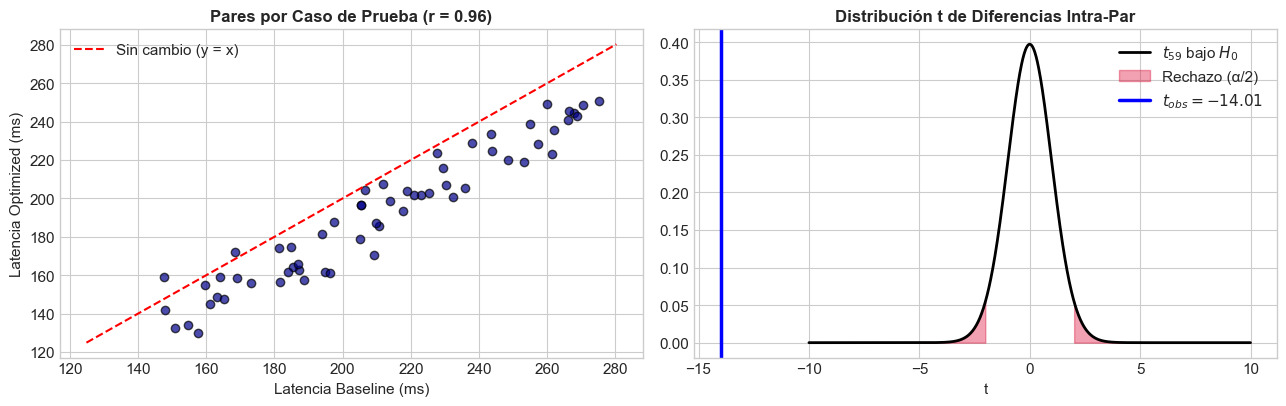

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))

# Panel 1: Gráfica de dispersión de pares (evidencia visual del emparejamiento)
ax1.scatter(base_paired, opt_paired, color='darkblue', alpha=0.7, edgecolors='k')
lims = [min(min(base_paired), min(opt_paired)) - 5, max(max(base_paired), max(opt_paired)) + 5]
ax1.plot(lims, lims, 'r--', lw=1.5, label='Sin cambio (y = x)')
ax1.set_xlabel('Latencia Baseline (ms)')
ax1.set_ylabel('Latencia Optimized (ms)')
ax1.set_title(f'Pares por Caso de Prueba (r = {correlacion:.2f})')
ax1.legend()

# Panel 2: Distribución nula t y estadístico observado
t_grid_p = np.linspace(-10, 10, 1000)
y_tp = stats.t.pdf(t_grid_p, df=df_paired)
ax2.plot(t_grid_p, y_tp, 'k-', lw=2, label=f'$t_{{{df_paired}}}$ bajo $H_0$')
ax2.fill_between(t_grid_p, 0, y_tp, where=(t_grid_p <= -t_crit_paired), color='crimson', alpha=0.4, label='Rechazo (α/2)')
ax2.fill_between(t_grid_p, 0, y_tp, where=(t_grid_p >= t_crit_paired), color='crimson', alpha=0.4)
ax2.axvline(t_calc_paired, color='blue', lw=2.5, label=f'$t_{{obs}} = {t_calc_paired:.2f}$')
ax2.set_title('Distribución t de Diferencias Intra-Par')
ax2.set_xlabel('t')
ax2.legend()

plt.tight_layout()
plt.show()


---

## 5. Diferencia de Dos Proporciones Poblacionales ($p_1 - p_2$) — Prueba $Z$

### 5.1 Contexto del Problema e Hipótesis
Un equipo de despliegue compara la tasa de fallas (error HTTP 5xx) entre dos arquitecturas de balanceo de carga:
* Balanceador A: $n_1 = 600$ solicitudes procesadas, con $k_1 = 36$ fallas ($\hat{p}_1 = 6.0\%$).
* Balanceador B (nuevo algoritmo): $n_2 = 700$ solicitudes procesadas, con $k_2 = 21$ fallas ($\hat{p}_2 = 3.0\%$).

Se desea contrastar si existe una diferencia estadísticamente significativa en la tasa de fallas:
$$H_0: p_1 - p_2 = 0 \quad (p_1 = p_2)$$
$$H_A: p_1 - p_2 \neq 0 \quad (p_1 \neq p_2)$$

Nivel de significancia: $\alpha = 0.05$.


In [18]:
# Datos del Caso 5
n1_prop, k1_prop = 600, 36
n2_prop, k2_prop = 700, 21

p1_hat = k1_prop / n1_prop
p2_hat = k2_prop / n2_prop
diff_prop = p1_hat - p2_hat

print(f"--- Muestra Caso 5: Dos Proporciones ---")
print(f"Balanceador A: n1 = {n1_prop}, fallas k1 = {k1_prop}, p̂1 = {p1_hat:.4f} ({p1_hat*100:.1f}%)")
print(f"Balanceador B: n2 = {n2_prop}, fallas k2 = {k2_prop}, p̂2 = {p2_hat:.4f} ({p2_hat*100:.1f}%)")
print(f"Diferencia muestral (p̂1 - p̂2): {diff_prop:.4f}")


--- Muestra Caso 5: Dos Proporciones ---
Balanceador A: n1 = 600, fallas k1 = 36, p̂1 = 0.0600 (6.0%)
Balanceador B: n2 = 700, fallas k2 = 21, p̂2 = 0.0300 (3.0%)
Diferencia muestral (p̂1 - p̂2): 0.0300


### 5.2 Cálculo "A Pie" (Paso a Paso)
Bajo la hipótesis nula $H_0: p_1 = p_2 = p$, la mejor estimación de la proporción común se obtiene agrupando los éxitos y observaciones de ambas muestras (**proporción combinada / pooled proportion**):
$$\hat{p}_{\text{pool}} = \frac{k_1 + k_2}{n_1 + n_2}$$

El error estándar bajo $H_0$ es:
$$SE_{\text{pool}} = \sqrt{\hat{p}_{\text{pool}} (1 - \hat{p}_{\text{pool}}) \left(\frac{1}{n_1} + \frac{1}{n_2}\right)}$$

El estadístico de prueba es:
$$Z_{\text{calc}} = \frac{\hat{p}_1 - \hat{p}_2}{SE_{\text{pool}}} \sim N(0, 1)$$


In [19]:
alpha_prop2 = 0.05

# 1. Proporción combinada bajo H0
p_pool = (k1_prop + k2_prop) / (n1_prop + n2_prop)

# 2. Error estándar agrupado
se_prop_pool = np.sqrt(p_pool * (1 - p_pool) * ((1 / n1_prop) + (1 / n2_prop)))

# 3. Estadístico Z observado
z_calc_prop2 = diff_prop / se_prop_pool

# 4. Valor crítico y P-valor
z_crit_prop2 = stats.norm.ppf(1 - alpha_prop2 / 2)
p_val_prop2 = 2 * stats.norm.sf(abs(z_calc_prop2))

print("=== CÁLCULO A PIE (PRUEBA Z DE DOS PROPORCIONES) ===")
print(f"Proporción combinada (p_pool):  {p_pool:.5f}")
print(f"Error estándar combinado (SE):  {se_prop_pool:.5f}")
print(f"Z calculado (Z_obs):            {z_calc_prop2:.4f}")
print(f"Valores críticos:               ±{z_crit_prop2:.4f}")
print(f"P-valor bilateral:              {p_val_prop2:.6f}")

decision_prop2 = "Rechazar H0" if abs(z_calc_prop2) > z_crit_prop2 else "No rechazar H0"
print(f"Decisión formal (α={alpha_prop2}):     {decision_prop2}")


=== CÁLCULO A PIE (PRUEBA Z DE DOS PROPORCIONES) ===
Proporción combinada (p_pool):  0.04385
Error estándar combinado (SE):  0.01139
Z calculado (Z_obs):            2.6336
Valores críticos:               ±1.9600
P-valor bilateral:              0.008449
Decisión formal (α=0.05):     Rechazar H0


### 5.3 Uso de Funciones Predefinidas (`statsmodels.stats.proportion.proportions_ztest`)
En `statsmodels`, la función `proportions_ztest` admite arrays o listas de conteos y tamaños muestrales `count=[k1, k2]` y `nobs=[n1, n2]`.


In [20]:
# Ejecución con statsmodels
z_sm_prop, p_sm_prop = proportions_ztest(count=[k1_prop, k2_prop], nobs=[n1_prop, n2_prop], alternative='two-sided')

tabla_prop2 = pd.DataFrame({
    'Método': [
        'A pie (fórmula canónica con p_pool)',
        'statsmodels proportions_ztest([k1, k2], [n1, n2])'
    ],
    'Estadístico Z': [z_calc_prop2, z_sm_prop],
    'P-valor': [p_val_prop2, p_sm_prop],
    'Diferencia absoluta': [0.0, abs(p_val_prop2 - p_sm_prop)],
    'Decisión (α=0.05)': [decision_prop2, "Rechazar H0" if p_sm_prop < alpha_prop2 else "No rechazar H0"]
})
tabla_prop2


,Método,Estadístico Z,P-valor,Diferencia absoluta,Decisión (α=0.05)
0,A pie (fórmula canónica con p_pool),2.63357,0.00845,0.0,Rechazar H0
1,"statsmodels proportions_ztest([k1, k2], [n1, n2])",2.63357,0.00845,0.0,Rechazar H0


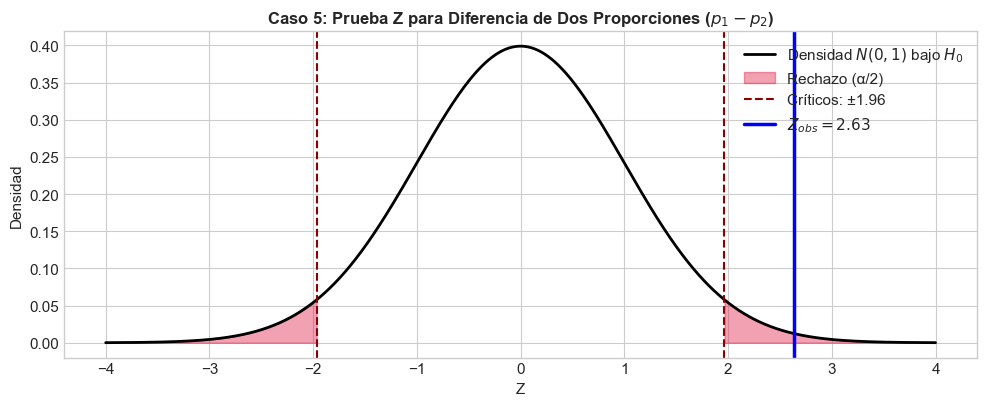

In [21]:
fig, ax = plt.subplots(figsize=(10, 4.2))
z_grid_p2 = np.linspace(-4, 4, 1000)
y_zp2 = stats.norm.pdf(z_grid_p2, 0, 1)

ax.plot(z_grid_p2, y_zp2, 'k-', lw=2, label='Densidad $N(0, 1)$ bajo $H_0$')
ax.fill_between(z_grid_p2, 0, y_zp2, where=(z_grid_p2 <= -z_crit_prop2), color='crimson', alpha=0.4, label='Rechazo (α/2)')
ax.fill_between(z_grid_p2, 0, y_zp2, where=(z_grid_p2 >= z_crit_prop2), color='crimson', alpha=0.4)
ax.axvline(-z_crit_prop2, color='darkred', linestyle='--', label=f'Críticos: ±{z_crit_prop2:.2f}')
ax.axvline(z_crit_prop2, color='darkred', linestyle='--')
ax.axvline(z_calc_prop2, color='blue', lw=2.5, label=f'$Z_{{obs}} = {z_calc_prop2:.2f}$')

ax.set_title('Caso 5: Prueba Z para Diferencia de Dos Proporciones ($p_1 - p_2$)')
ax.set_xlabel('Z')
ax.set_ylabel('Densidad')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()


---

## 6. Comparación / Razón de Dos Varianzas ($\sigma_1^2 / \sigma_2^2$) — Prueba $F$ de Fisher y Prueba de Levene

### 6.1 Contexto del Problema e Hipótesis
Antes de decidir si se puede aplicar la prueba $t$ agrupada de Student (que asume $\sigma_1^2 = \sigma_2^2$) o si se debe emplear la prueba $t$ de Welch (que no la asume), es fundamental comparar la dispersión de las dos poblaciones.

$$H_0: \frac{\sigma_1^2}{\sigma_2^2} = 1 \quad (\sigma_1^2 = \sigma_2^2)$$
$$H_A: \frac{\sigma_1^2}{\sigma_2^2} \neq 1 \quad (\sigma_1^2 \neq \sigma_2^2)$$

Nivel de significancia: $\alpha = 0.05$.

**Supuesto clave:** La prueba $F$ clásica depende críticamente del supuesto de que ambas poblaciones son normales. Si existen desviaciones de normalidad, se prefiere la **prueba de Levene** o la prueba de Brown-Forsythe.


In [22]:
# Simulación sintética del Caso 6
np.random.seed(99)
n1_f, n2_f = 35, 30

# Simulación: Grupo 1 tiene sigma = 14 ms, Grupo 2 tiene sigma = 8 ms
sample1_f = stats.norm.rvs(loc=100.0, scale=14.0, size=n1_f, random_state=99)
sample2_f = stats.norm.rvs(loc=102.0, scale=8.0, size=n2_f, random_state=199)

s1_sq = np.var(sample1_f, ddof=1)
s2_sq = np.var(sample2_f, ddof=1)
df1_f = n1_f - 1
df2_f = n2_f - 1

print(f"--- Muestra Caso 6: Comparación de Varianzas ---")
print(f"Grupo 1: n1 = {n1_f}, s1² = {s1_sq:.4f} (s1 = {np.sqrt(s1_sq):.4f})")
print(f"Grupo 2: n2 = {n2_f}, s2² = {s2_sq:.4f} (s2 = {np.sqrt(s2_sq):.4f})")
print(f"Cociente muestral (s1² / s2²): {s1_sq / s2_sq:.4f}")


--- Muestra Caso 6: Comparación de Varianzas ---
Grupo 1: n1 = 35, s1² = 150.7499 (s1 = 12.2780)
Grupo 2: n2 = 30, s2² = 85.1783 (s2 = 9.2292)
Cociente muestral (s1² / s2²): 1.7698


### 6.2 Cálculo "A Pie" de la Prueba $F$ (Paso a Paso)
Bajo $H_0$ y normalidad, el cociente de varianzas muestrales sigue una distribución $F$ de Fisher-Snedecor con $(df_1, df_2)$ grados de libertad:
$$F_{\text{calc}} = \frac{s_1^2}{s_2^2} \sim F(n_1 - 1, n_2 - 1)$$

* **Valores críticos bilaterales**:
  * Crítico inferior: $F_{\text{crit, low}} = \text{stats.f.ppf}(\alpha/2, df_1, df_2)$
  * Crítico superior: $F_{\text{crit, upp}} = \text{stats.f.ppf}(1 - \alpha/2, df_1, df_2)$
* **P-valor bilateral**:
  $$p = 2 \times \min\left(P(F \le F_{\text{calc}}), P(F \ge F_{\text{calc}})\right)$$


In [23]:
alpha_f = 0.05

# 1. Estadístico F calculado
f_calc = s1_sq / s2_sq

# 2. Valores críticos bilaterales
f_crit_low = stats.f.ppf(alpha_f / 2, dfn=df1_f, dfd=df2_f)
f_crit_upp = stats.f.ppf(1 - alpha_f / 2, dfn=df1_f, dfd=df2_f)

# 3. P-valor exacto
p_val_f = 2 * min(stats.f.cdf(f_calc, dfn=df1_f, dfd=df2_f), stats.f.sf(f_calc, dfn=df1_f, dfd=df2_f))

print("=== CÁLCULO A PIE (PRUEBA F DE DOS VARIANZAS) ===")
print(f"F calculado (s1²/s2²): {f_calc:.4f}")
print(f"Valores críticos:       [{f_crit_low:.4f}, {f_crit_upp:.4f}]")
print(f"P-valor bilateral:      {p_val_f:.6f}")

decision_f = "Rechazar H0 (Varianzas desiguales)" if (f_calc < f_crit_low or f_calc > f_crit_upp) else "No rechazar H0"
print(f"Decisión formal:        {decision_f}")


=== CÁLCULO A PIE (PRUEBA F DE DOS VARIANZAS) ===
F calculado (s1²/s2²): 1.7698
Valores críticos:       [0.4949, 2.0623]
P-valor bilateral:      0.120460
Decisión formal:        No rechazar H0


### 6.3 Uso de Funciones Predefinidas (Función Modular y `scipy.stats.levene`)
SciPy provee `scipy.stats.levene` (usando por defecto la mediana o media para mayor robustez ante distribuciones con colas pesadas o asimetría). Asimismo empaquetamos `f_test_2samp_variance` para la prueba $F$ clásica.


In [24]:
def f_test_2samp_variance(data1, data2, alternative='two-sided'):
    """Prueba F clásica de Fisher para igualdad de varianzas en dos poblaciones normales."""
    x1, x2 = np.asarray(data1), np.asarray(data2)
    s1_2 = np.var(x1, ddof=1)
    s2_2 = np.var(x2, ddof=1)
    df1 = len(x1) - 1
    df2 = len(x2) - 1
    stat = s1_2 / s2_2
    
    if alternative == 'two-sided':
        pval = 2 * min(stats.f.cdf(stat, df1, df2), stats.f.sf(stat, df1, df2))
    elif alternative == 'greater':
        pval = stats.f.sf(stat, df1, df2)
    elif alternative == 'less':
        pval = stats.f.cdf(stat, df1, df2)
    else:
        raise ValueError("alternative debe ser 'two-sided', 'greater' o 'less'")
    return {'statistic': stat, 'pvalue': pval, 'df1': df1, 'df2': df2}

# 1. Prueba F empaquetada
res_f_pkg = f_test_2samp_variance(sample1_f, sample2_f)

# 2. Prueba de Levene (robusta ante desviaciones de normalidad)
stat_levene, p_levene = stats.levene(sample1_f, sample2_f, center='median')

tabla_var2 = pd.DataFrame({
    'Prueba': [
        'Prueba F de Fisher (A pie)',
        'Prueba F empaquetada (f_test_2samp_variance)',
        'Prueba de Levene (scipy.stats.levene, robusta)'
    ],
    'Estadístico': [f"F = {f_calc:.4f}", f"F = {res_f_pkg['statistic']:.4f}", f"W = {stat_levene:.4f}"],
    'P-valor': [p_val_f, res_f_pkg['pvalue'], p_levene],
    'Decisión (α=0.05)': [
        decision_f,
        "Rechazar H0 (Varianzas desiguales)" if res_f_pkg['pvalue'] < alpha_f else "No rechazar H0",
        "Rechazar H0 (Varianzas desiguales)" if p_levene < alpha_f else "No rechazar H0"
    ]
})
tabla_var2


,Prueba,Estadístico,P-valor,Decisión (α=0.05)
0,Prueba F de Fisher (A pie),F = 1.7698,0.12046,No rechazar H0
1,Prueba F empaquetada (f_test_2samp_variance),F = 1.7698,0.12046,No rechazar H0
2,"Prueba de Levene (scipy.stats.levene, robusta)",W = 0.6622,0.41884,No rechazar H0


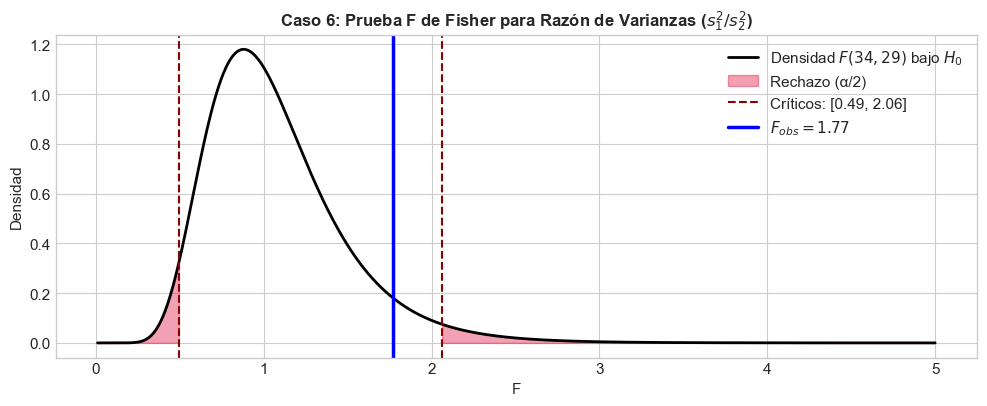

In [25]:
fig, ax = plt.subplots(figsize=(10, 4.2))
f_grid = np.linspace(0.01, 5, 1000)
y_f = stats.f.pdf(f_grid, dfn=df1_f, dfd=df2_f)

ax.plot(f_grid, y_f, 'k-', lw=2, label=f'Densidad $F({df1_f}, {df2_f})$ bajo $H_0$')
ax.fill_between(f_grid, 0, y_f, where=(f_grid <= f_crit_low), color='crimson', alpha=0.4, label='Rechazo (α/2)')
ax.fill_between(f_grid, 0, y_f, where=(f_grid >= f_crit_upp), color='crimson', alpha=0.4)
ax.axvline(f_crit_low, color='darkred', linestyle='--')
ax.axvline(f_crit_upp, color='darkred', linestyle='--', label=f'Críticos: [{f_crit_low:.2f}, {f_crit_upp:.2f}]')
ax.axvline(f_calc, color='blue', lw=2.5, label=f'$F_{{obs}} = {f_calc:.2f}$')

ax.set_title('Caso 6: Prueba F de Fisher para Razón de Varianzas ($s_1^2 / s_2^2$)')
ax.set_xlabel('F')
ax.set_ylabel('Densidad')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()


---

## 7. Tabla Resumen y Guía de Selección para Pruebas de Dos Poblaciones

| Comparación | Hipótesis Nula ($H_0$) | Estadístico de Prueba | Distribución bajo $H_0$ | Cálculo "A Pie" (SciPy) | Función Predefinida en Python | Supuestos Clave |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **Medias independientes con $\sigma_1, \sigma_2$ conocidas** | $\mu_1 - \mu_2 = \Delta_0$ | $Z = \frac{(\bar{x}_1 - \bar{x}_2) - \Delta_0}{\sqrt{\sigma_1^2/n_1 + \sigma_2^2/n_2}}$ | $N(0, 1)$ | `stats.norm.sf` / `ppf` | `ztest_2samp_known_sd` | Independencia dentro y entre grupos; poblaciones normales o muestras grandes ($n_i \ge 30$). $\sigma_1, \sigma_2$ conocidas. |
| **Medias independientes, varianzas iguales desconocidas** | $\mu_1 - \mu_2 = \Delta_0$ | $t = \frac{(\bar{x}_1 - \bar{x}_2) - \Delta_0}{s_p \sqrt{1/n_1 + 1/n_2}}$ | $t_{n_1 + n_2 - 2}$ | `stats.t.sf` / `ppf` | `scipy.stats.ttest_ind(..., equal_var=True)` | Independencia entre y dentro de grupos; normalidad aproximada; homogeneidad de varianzas ($\sigma_1^2 = \sigma_2^2$). |
| **Medias independientes, varianzas desiguales desconocidas (Welch)** | $\mu_1 - \mu_2 = \Delta_0$ | $t = \frac{(\bar{x}_1 - \bar{x}_2) - \Delta_0}{\sqrt{s_1^2/n_1 + s_2^2/n_2}}$ | $t_{df_{\text{Welch}}}$ | `stats.t.sf(..., df=df_w)` | `scipy.stats.ttest_ind(..., equal_var=False)` | Independencia entre y dentro de grupos; normalidad aproximada. **No asume varianzas iguales**. (Recomendada por defecto). |
| **Medias pareadas / dependientes** | $\mu_d = 0$ | $t = \frac{\bar{d} - 0}{s_d / \sqrt{n}}$ | $t_{n-1}$ | `stats.t.sf(..., df=n-1)` | `scipy.stats.ttest_rel` o `ttest_1samp` en diffs | Pares legítimos uno a uno; las diferencias $d_i$ deben ser independientes y aproximadamente normales para muestras pequeñas. |
| **Dos proporciones ($p_1 - p_2$)** | $p_1 - p_2 = 0$ | $Z = \frac{\hat{p}_1 - \hat{p}_2}{\sqrt{\hat{p}_{\text{pool}}(1-\hat{p}_{\text{pool}})(1/n_1 + 1/n_2)}}$ | $N(0, 1)$ | `stats.norm.sf` / `ppf` | `statsmodels.stats.proportion.proportions_ztest` | Muestras independientes; muestras suficientemente grandes ($n_i p_i \ge 5$ y $n_i (1-p_i) \ge 5$). |
| **Dos varianzas ($\sigma_1^2 / \sigma_2^2$)** | $\frac{\sigma_1^2}{\sigma_2^2} = 1$ | $F = \frac{s_1^2}{s_2^2}$ | $F_{n_1-1, n_2-1}$ | `stats.f.sf` / `ppf` | `f_test_2samp_variance` / `scipy.stats.levene` | **Normalidad estricta** para prueba $F$. Si hay sospecha razonable de no normalidad, usar Levene centrada en la mediana. |

### Criterio Rector del Diseño
* **El diseño metodológico determina la prueba:** No se debe elegir entre una prueba de grupos independientes y una prueba pareada según cuál arroje el menor p-valor (*p-hacking*).
* Si las observaciones corresponden a los **mismos casos** bajo distintas condiciones, el análisis debe realizarse **sobre las diferencias intra-caso** (prueba pareada). Si corresponden a **entidades distintas**, se debe emplear **Welch** como estándar moderno.
